In [14]:
import os
import gc
import rasterio
import numpy as np
import torch
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [ ]:

uav_files = [
    '../Wegrzce_tify/01W1008.tif',
    '../Wegrzce_tify/01W0209.tif',
    '../Wegrzce_tify/01W0909.tif',
    '../Wegrzce_tify/01W1509.tif',
    '../Wegrzce_tify/01W0110.tif',
    '../Wegrzce_tify/01W0310.tif',
    '../Wegrzce_tify/01W0610.tif',
    '../Wegrzce_tify/01W2710.tif'
]

output_dir = 'Wegrzce_maski_stresu'
os.makedirs(output_dir, exist_ok=True)

UAV_BANDS = {
    'blue_450': 3, 'green_531': 7, 'green_570': 9,
    'red_680': 15, 're_705': 16, 'nir_750': 18, 'nir_800': 21
}

FEATURE_NAMES = ['NDVI', 'EVI', 'SAVI', 'RENDVI', 'PRI', 'CIre', 'NDWI']
NDVI_SOIL_THRESHOLD = 0.15  # Próg odcięcia gołej gleby (dostosuj w razie potrzeby)
SAMPLES_PER_IMAGE = 50000   # Liczba pikseli losowanych z każdego zdjęcia do nauki

In [24]:
def compute_uav_indices(tif_path):
    """Wczytuje pasma dla jednego pliku, liczy wskaźniki i zwraca je wraz z metadanymi."""
    d = {}
    with rasterio.open(tif_path) as src:
        meta = src.meta.copy()
        for name, b_idx in UAV_BANDS.items():
            band = src.read(b_idx).astype('float32')
            if src.nodata is not None:
                band[band == src.nodata] = np.nan
            band[band == 0] = np.nan
            d[name] = band
            
    eps = 1e-8
    ind = {}
    ind['NDVI'] = (d['nir_800'] - d['red_680']) / (d['nir_800'] + d['red_680'] + eps)
    ind['EVI'] = 2.5 * ((d['nir_800'] - d['red_680']) / (d['nir_800'] + 6 * d['red_680'] - 7.5 * d['blue_450'] + 1 + eps))
    L = 0.50
    ind['SAVI'] = ((d['nir_800'] - d['red_680']) / (d['nir_800'] + d['red_680'] + L + eps)) * (1 + L)
    ind['RENDVI'] = (d['nir_750'] - d['re_705']) / (d['nir_750'] + d['re_705'] + eps)
    ind['PRI'] = (d['green_531'] - d['green_570']) / (d['green_531'] + d['green_570'] + eps)
    ind['CIre'] = (d['nir_800'] / (d['re_705'] + eps)) - 1.0
    ind['NDWI'] = (d['green_570'] - d['nir_800']) / (d['green_570'] + d['nir_800'] + eps)
    
    del d
    gc.collect()
    return ind, meta

In [25]:
# ==========================================
# 2. ETAP 1: ZBIERANIE PRÓBEK ZE WSZYSTKICH ZDJĘĆ
# ==========================================
print("Etap 1: Losowanie pikseli roślinności z 4 zdjęć do treningu...")
sampled_features = []

for path in uav_files:
    if not os.path.exists(path):
        print(f"Pominięto (brak pliku): {path}")
        continue
        
    print(f" -> Próbkowanie z: {path}")
    indices, _ = compute_uav_indices(path)
    
    # Tworzymy maskę czystej roślinności (brak NaN oraz NDVI powyżej progu gleby)
    valid_mask = (~np.isnan(indices['NDVI'])) & (indices['NDVI'] > NDVI_SOIL_THRESHOLD)
    
    # Układamy macierz cech (Liczba_pikseli_roślin, 7_wskaźników)
    X_valid = np.column_stack([indices[f][valid_mask] for f in FEATURE_NAMES])
    
    # Dodatkowe czyszczenie ewentualnych wartości nieskończonych (inf) z dzielenia
    finite_mask = np.all(np.isfinite(X_valid), axis=1)
    X_valid = X_valid[finite_mask]
    
    # Losujemy podzbiór pikseli, aby nie zapchać RAM-u
    if len(X_valid) > SAMPLES_PER_IMAGE:
        idx = np.random.choice(len(X_valid), SAMPLES_PER_IMAGE, replace=False)
        X_sample = X_valid[idx]
    else:
        X_sample = X_valid
        
    sampled_features.append(X_sample)
    
    # Zwalnianie pamięci przed kolejnym zdjęciem
    del indices, X_valid, valid_mask
    gc.collect()

# Łączymy próbki ze wszystkich 4 zdjęć w jedną tabelę treningową
X_train_all = np.vstack(sampled_features)
print(f"Zebrano łącznie {X_train_all.shape[0]} pikseli do nauki modelu.")

Etap 1: Losowanie pikseli roślinności z 4 zdjęć do treningu...
 -> Próbkowanie z: ../Wegrzce_tify/01W1509.tif
 -> Próbkowanie z: ../Wegrzce_tify/01W0110.tif
 -> Próbkowanie z: ../Wegrzce_tify/01W0310.tif
 -> Próbkowanie z: ../Wegrzce_tify/01W0610.tif
Zebrano łącznie 200000 pikseli do nauki modelu.


In [26]:
# ==========================================
# 3. TRENING MODELU K-MEANS (STANDARYZACJA + KLASTROWANIE)
# ==========================================
# Standaryzacja jest konieczna, bo PRI ma zakres (-0.1, 0.1), a CIre (0, 3)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_all)

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train_scaled)

# Sprawdzamy, który klaster oznacza STRES (ten, który ma niższą średnią wartość CIre / NDVI)
cire_idx = FEATURE_NAMES.index('CIre')
cluster_0_cire = X_train_all[kmeans.labels_ == 0, cire_idx].mean()
cluster_1_cire = X_train_all[kmeans.labels_ == 1, cire_idx].mean()

stress_cluster_label = 0 if cluster_0_cire < cluster_1_cire else 1
print(f"Średnie CIre -> Klaster 0: {cluster_0_cire:.3f}, Klaster 1: {cluster_1_cire:.3f}")
print(f"Klaster oznaczający STRES (słabszą kondycję) to: {stress_cluster_label}\n")

Średnie CIre -> Klaster 0: -0.041, Klaster 1: 0.366
Klaster oznaczający STRES (słabszą kondycję) to: 0



Etap 2: Klasyfikacja pełnych ortofotomap i generowanie podglądu...
 -> Klasyfikacja i rysowanie: 01W1509.tif
 -> Klasyfikacja i rysowanie: 01W0110.tif
 -> Klasyfikacja i rysowanie: 01W0310.tif
 -> Klasyfikacja i rysowanie: 01W0610.tif


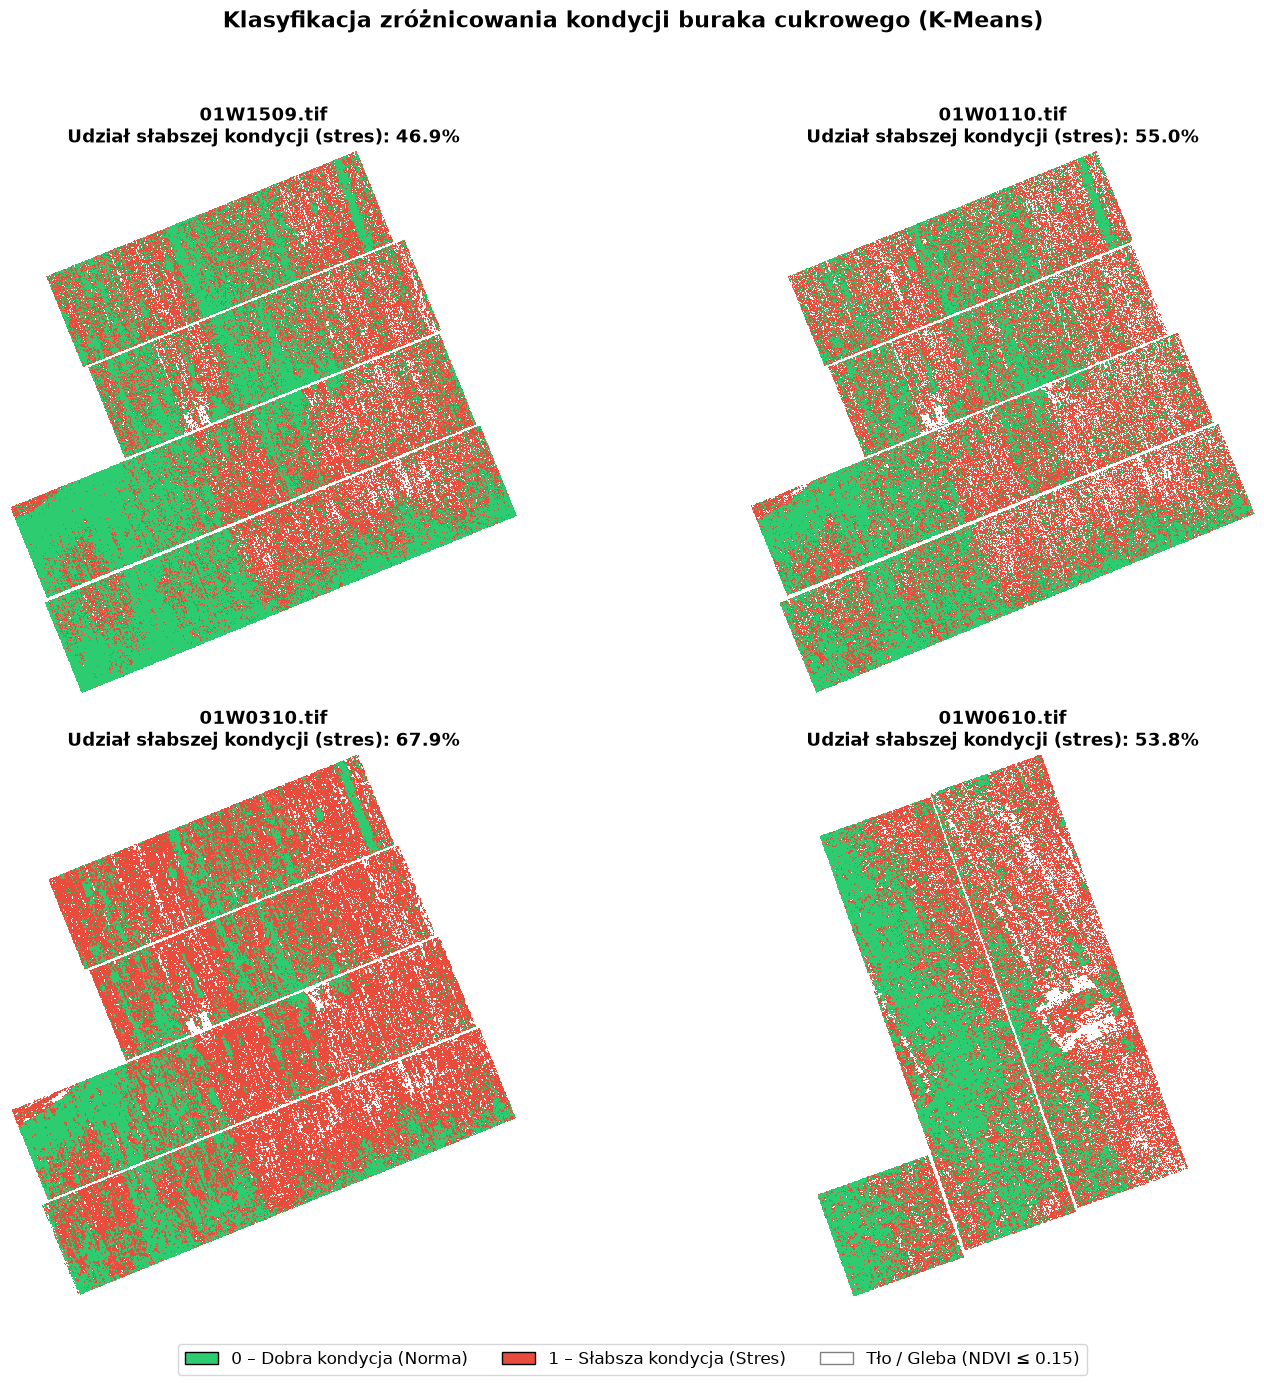

In [ ]:
# ==========================================
# 4. ETAP 2: KLASYFIKACJA I WIZUALIZACJA (BEZ ZAPISU NA DYSK)
# ==========================================
print("Etap 2: Klasyfikacja pełnych ortofotomap i generowanie podglądu...")

fig, axes = plt.subplots(4, 2, figsize=(16, 14))
axes = axes.flatten()

# Paleta: Zielony (0) = Dobra kondycja, Czerwony (1) = Stres, Biały = Tło/Gleba (NaN)
cmap = ListedColormap(['#2ecc71', '#e74c3c'])
cmap.set_bad(color='white')

# Co który piksel przesyłamy do wyświetlenia (chroni przed crashem Matplotliba)
step = 10 

for i, path in enumerate(uav_files):
    if not os.path.exists(path):
        print(f"Pominięto (brak pliku): {path}")
        axes[i].axis('off')
        continue
        
    filename = os.path.basename(path)
    print(f" -> Klasyfikacja i rysowanie: {filename}")
    
    indices, _ = compute_uav_indices(path)
    shape = indices['NDVI'].shape
    
    # Maska ważnych pikseli roślinnych
    valid_mask = (~np.isnan(indices['NDVI'])) & (indices['NDVI'] > NDVI_SOIL_THRESHOLD)
    for f in FEATURE_NAMES:
        valid_mask &= np.isfinite(indices[f])
        
    # Macierz do wizualizacji wypełniona NaN (białe tło i gleba)
    stress_preview = np.full(shape, np.nan, dtype='float32')
    
    # Wyciągamy piksele do predykcji
    X_full = np.column_stack([indices[f][valid_mask] for f in FEATURE_NAMES])
    del indices # Od razu zwalniamy pamięć po wskaźnikach
    gc.collect()
    
    X_full_scaled = scaler.transform(X_full)
    preds = kmeans.predict(X_full_scaled)
    
    # Mapujemy wynik: 1 = STRES (słaba kondycja), 0 = ZDROWA ROŚLINA
    final_classes = np.where(preds == stress_cluster_label, 1.0, 0.0).astype('float32')
    stress_preview[valid_mask] = final_classes
    
    # Obliczamy odsetek roślin w stresie na danym zdjęciu
    stress_ratio = (final_classes == 1.0).mean() * 100
    
    # Rysujemy pomniejszony podgląd [::step, ::step]
    axes[i].imshow(stress_preview[::step, ::step], cmap=cmap, vmin=0, vmax=1, interpolation='nearest')
    axes[i].set_title(f"{filename}\nUdział słabszej kondycji (stres): {stress_ratio:.1f}%", fontsize=13, fontweight='bold')
    axes[i].axis('off')
    
    # Czyszczenie RAM-u przed kolejnym zdjęciem
    del X_full, X_full_scaled, preds, final_classes, stress_preview, valid_mask
    gc.collect()

# Wspólna, czytelna legenda na dole wykresu
legend_elements = [
    Patch(facecolor='#2ecc71', edgecolor='black', label='0 – Dobra kondycja (Norma)'),
    Patch(facecolor='#e74c3c', edgecolor='black', label='1 – Słabsza kondycja (Stres)'),
    Patch(facecolor='white', edgecolor='gray', label='Tło / Gleba (NDVI ≤ 0.15)')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3, fontsize=12, frameon=True)

plt.suptitle('Klasyfikacja zróżnicowania kondycji buraka cukrowego (K-Means)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()